In [1]:
# First step import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy
print("Lets Goooo!")

Lets Goooo!


In [2]:
from getpass import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# A box will appear at the top of VS Code asking for your password. Type it and press Enter.
password = getpass("PostgreSQL password: ")

url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="yelp_project",
)
engine = create_engine(url)

# Ask the database one simple question to prove the connection works
with engine.connect() as conn:
    rows = conn.execute(text("SELECT COUNT(*) FROM clean.reviews")).scalar()
print("Connected. Reviews in clean.reviews:", rows)

Connected. Reviews in clean.reviews: 307510


In [4]:
import sys
print(sys.executable)

C:\Users\DELL PC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe


In [ ]:
# CHECKING THE CONNECTION AND IMPORTING LIBRARIES


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# --- connect to the database (the password is never saved in the file) ---
password = getpass("PostgreSQL password: ")
engine = create_engine(URL.create(
    "postgresql+psycopg2", username="postgres", password=password,
    host="localhost", port=5432, database="yelp_project"))

# --- load the four clean tables (the reviews table takes 10-30 seconds) ---
business   = pd.read_sql("SELECT * FROM clean.business", engine)
users      = pd.read_sql("SELECT * FROM clean.users", engine)
reviews    = pd.read_sql("SELECT * FROM clean.reviews", engine)
categories = pd.read_sql("SELECT * FROM clean.business_categories", engine)

# --- check the shapes: (rows, columns) ---
print("business  ", business.shape)
print("users     ", users.shape)
print("reviews   ", reviews.shape)
print("categories", categories.shape)

business   (52263, 13)
users      (214971, 8)
reviews    (307510, 17)
categories (243587, 2)


In [7]:
# What we’re doing: before making any chart, check the column types, count the missing values,
#  and read the summary numbers. This is the Python version of the profiling you did in SQL, 
# and it also confirms nothing changed on the way in.


# --- 1) column names and types of the reviews table
print(reviews.dtypes)

# --- 2) missing values, as COUNTS (a percentage would round tiny numbers to 0)
for name, df in [("business", business), ("users", users), ("reviews", reviews) , ("categories", categories)]:
    miss = df.isna().sum()
    print(f"{name}: missing ->", miss[miss > 0].to_dict() or "none")

# --- 3) summary of the number columns
print(reviews[["stars", "text_length", "useful_votes"]].describe().round(2))
print(business[["business_stars", "total_reviews_all_time"]].describe().round(2))


review_id                  object
user_id                    object
business_id                object
stars                       int64
star_group                 object
review_datetime    datetime64[ns]
review_date                object
review_year                 int64
review_month                int64
is_partial_year             int64
useful_votes                int64
funny_votes                 int64
cool_votes                  int64
review_text                object
text_length                 int64
is_short_review             int64
has_url                     int64
dtype: object
business: missing -> {'postal_code': 21}
users: missing -> {'total_reviews_all_time': 2}
reviews: missing -> none
categories: missing -> none
           stars  text_length  useful_votes
count  307510.00    307510.00     307510.00
mean        3.79       544.41          0.98
std         1.39       502.66          2.58
min         1.00         1.00          0.00
25%         3.00       218.00          0.00
50

stars
1    12.0
2     8.6
3    11.5
4    23.9
5    44.0
Name: proportion, dtype: float64


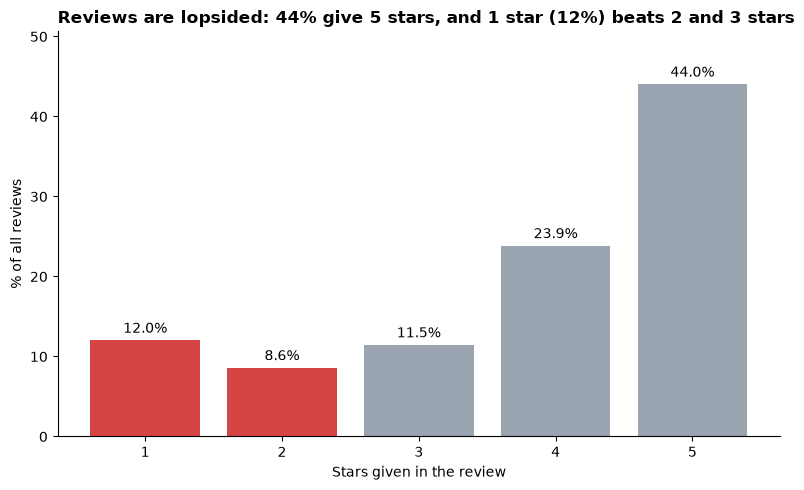

negative share (1-2 stars): 20.6 %


In [8]:
# What we’re doing: 
# before comparing states or years, we need to know what a normal review looks like. 
# This is the baseline everything else gets measured against.


# 1) what share of all reviews gives each star rating?
share = reviews["stars"].value_counts(normalize=True).sort_index() * 100
print(share.round(1))

# 2) draw it: red = negative (1-2 stars), grey = everything else
colors = ["#D64545" if s <= 2 else "#9AA5B1" for s in share.index]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(share.index, share.values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Stars given in the review")
ax.set_ylabel("% of all reviews")
ax.set_title(f"Reviews are lopsided: {share[5]:.0f}% give 5 stars, and 1 star ({share[1]:.0f}%) beats 2 and 3 stars",
             loc="left", fontsize=12, fontweight="bold")
ax.set_ylim(0, share.max() * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

print("negative share (1-2 stars):", round(share[[1, 2]].sum(), 1), "%")